
## 1. Data source and scope

The Bureau of Labor Statistics (BLS) Local Area Unemployment Statistics (LAUS) program provides estimates of employment, unemployment, and labor force characteristics.

**Source:** [BLS Local Area Unemployment Statistics](https://www.bls.gov/lau/)

**Dataset:** `staadata.xlsx` - *States and selected areas: Employment status of the civilian noninstitutional population, 1976–2025 annual averages.*

Each observation represents one geographic area in one year. The analysis focuses on the 50 US states over 2014–2025.

**Data limitation (2025):** Annual estimates for 2025 are based on 11 months, excluding October. Data for October 2025 were not collected because of the federal government shutdown. Consequently, the 2025 estimates are not based on the same 12-month coverage as previous years.


## 2. Data overview

Five labor market indicators are selected:

| Indicator | Description |
|---|---|
| `labor_force` | Number of people employed or unemployed and actively seeking work |
| `labor_force_participation_rate` | Labor force as a percentage of the civilian noninstitutional population aged 16+ |
| `employment` | Number of employed residents |
| `unemployment` | Number of unemployed residents |
| `unemployment_rate` | Unemployed people as a percentage of the civilian labor force |

The dataset also retains `state_fips`, `state`, and `year` for geographic and temporal integration with other data sources.

LAUS employment measures employed residents rather than jobs located at business establishments.


In [9]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px


In [10]:
# Load LAUS data using the verified workbook structure
PROJECT_ROOT = Path.cwd().resolve().parents[1]
LAUS_FILE = PROJECT_ROOT / "data" / "raw" / "bls" / "laus" / "extracted" / "staadata.xlsx"

columns = [
    "state_fips", "state", "year", "civilian_population",
    "labor_force", "labor_force_participation_rate",
    "employment", "employment_population_ratio",
    "unemployment", "unemployment_rate"
]

laus_raw = pd.read_excel(
    LAUS_FILE,
    sheet_name="staadata",
    header=None,
    skiprows=8,
    names=columns,
    dtype={"state_fips": str}
)


# Extract the four-digit year, removing footnote markers
laus_raw["year"] = pd.to_numeric(
    laus_raw["year"].astype(str).str.extract(r"^\s*(\d{4})")[0],
    errors="coerce"
)

selected_columns = [
    "state_fips", "state", "year",
    "civilian_population",
    "labor_force", "labor_force_participation_rate",
    "employment", "employment_population_ratio",
    "unemployment", "unemployment_rate"
]

laus_overview = laus_raw.loc[
    laus_raw["year"].between(2014, 2025),
    selected_columns
].copy()

display(laus_overview.head())


,state_fips,state,year,civilian_population,labor_force,labor_force_participation_rate,employment,employment_population_ratio,unemployment,unemployment_rate
2014,01,Alabama,2014.0,3808783.0,2169091.0,56.9,2022380.0,53.1,146711.0,6.8
2015,02,Alaska,2014.0,539490.0,363723.0,67.4,339230.0,62.9,24493.0,6.7
2016,04,Arizona,2014.0,5101564.0,3055190.0,59.9,2846407.0,55.8,208783.0,6.8
2017,05,Arkansas,2014.0,2277964.0,1323986.0,58.1,1246128.0,54.7,77858.0,5.9
2018,06,California,2014.0,29986988.0,18697592.0,62.4,17282882.0,57.6,1414710.0,7.6


## 3. Data quality

The dataset is checked for geographic coverage, missing values, and duplicate observations. The analysis is restricted to the 50 US states and the period 2014–2025.


In [11]:
# Identify the 50 US states using FIPS codes
state_fips_codes = {
    "01", "02", "04", "05", "06", "08", "09", "10", "12", "13",
    "15", "16", "17", "18", "19", "20", "21", "22", "23", "24",
    "25", "26", "27", "28", "29", "30", "31", "32", "33", "34",
    "35", "36", "37", "38", "39", "40", "41", "42", "44", "45",
    "46", "47", "48", "49", "50", "51", "53", "54", "55", "56"
}

# Inspect geographic areas excluded from the analysis
excluded_areas = (
    laus_overview.loc[
        ~laus_overview["state_fips"].isin(state_fips_codes),
        ["state_fips", "state"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total geographic areas:", laus_overview["state_fips"].nunique())
print("US states:", laus_overview.loc[
    laus_overview["state_fips"].isin(state_fips_codes),
    "state_fips"
].nunique())

display(excluded_areas)


Total geographic areas: 53
US states: 50


,state_fips,state
0,037,Los Angeles County
1,11,District of Columbia
2,51000,New York city


### 3.2 Missing values and duplicates

Data completeness is assessed for the 50 US states over 2014–2025. The checks include missing values, duplicate state–year records, and geographic and temporal coverage.


In [12]:
# Filter the 50 US states
laus_state = laus_overview.loc[
    laus_overview["state_fips"].isin(state_fips_codes)
].copy()

laus_state["year"] = laus_state["year"].astype(int)

# Validate numeric indicators

indicators = [
    "civilian_population",
    "labor_force",
    "labor_force_participation_rate",
    "employment",
    "employment_population_ratio",
    "unemployment",
    "unemployment_rate"
]


laus_state[indicators] = laus_state[indicators].apply(
    pd.to_numeric, errors="coerce"
)

quality_summary = pd.DataFrame([{
    "states": laus_state["state_fips"].nunique(),
    "years": laus_state["year"].nunique(),
    "observations": len(laus_state),
    "missing_values": int(laus_state.isna().sum().sum()),
    "duplicate_state_year": int(
        laus_state.duplicated(["state_fips", "year"]).sum()
    ),
    "first_year": laus_state["year"].min(),
    "last_year": laus_state["year"].max()
}])

display(quality_summary)


,states,years,observations,missing_values,duplicate_state_year,first_year,last_year
0,50,12,600,0,0,2014,2025


## 4. Data preparation and visualization


### 4.1 Data preparation

The original estimates are retained without imputation or adjustment. The 2025 observations remain subject to the 11-month coverage limitation described in Section 1.


In [13]:
# Standardize and order the final dataset
laus_state = (
    laus_state[
        ["state_fips", "state", "year",
         "civilian_population",
         "labor_force", "labor_force_participation_rate",
         "employment", "employment_population_ratio",
         "unemployment", "unemployment_rate"]
    ]
    .sort_values(["state_fips", "year"])
    .reset_index(drop=True)
)


# Validate the final panel structure
assert len(laus_state) == 600
assert not laus_state.duplicated(["state_fips", "year"]).any()
assert laus_state.notna().all().all()

display(laus_state.head())


,state_fips,state,year,civilian_population,labor_force,labor_force_participation_rate,employment,employment_population_ratio,unemployment,unemployment_rate
0,01,Alabama,2014,3808783.0,2169091.0,56.9,2022380.0,53.1,146711.0,6.8
1,01,Alabama,2015,3831201.0,2172619.0,56.7,2040087.0,53.2,132532.0,6.1
2,01,Alabama,2016,3855107.0,2196496.0,57.0,2069474.0,53.7,127022.0,5.8
3,01,Alabama,2017,3878867.0,2207267.0,56.9,2107659.0,54.3,99608.0,4.5
4,01,Alabama,2018,3900125.0,2236161.0,57.3,2148823.0,55.1,87338.0,3.9


### 4.2 Selected visualizations



In [14]:
# Prepare geographic identifiers for Plotly
state_abbreviations = {
    "01": "AL", "02": "AK", "04": "AZ", "05": "AR", "06": "CA",
    "08": "CO", "09": "CT", "10": "DE", "12": "FL", "13": "GA",
    "15": "HI", "16": "ID", "17": "IL", "18": "IN", "19": "IA",
    "20": "KS", "21": "KY", "22": "LA", "23": "ME", "24": "MD",
    "25": "MA", "26": "MI", "27": "MN", "28": "MS", "29": "MO",
    "30": "MT", "31": "NE", "32": "NV", "33": "NH", "34": "NJ",
    "35": "NM", "36": "NY", "37": "NC", "38": "ND", "39": "OH",
    "40": "OK", "41": "OR", "42": "PA", "44": "RI", "45": "SC",
    "46": "SD", "47": "TN", "48": "TX", "49": "UT", "50": "VT",
    "51": "VA", "53": "WA", "54": "WV", "55": "WI", "56": "WY"
}

unemployment_map = laus_state.copy()
unemployment_map["state_abbr"] = (
    unemployment_map["state_fips"].map(state_abbreviations)
)

fig = px.choropleth(
    unemployment_map,
    locations="state_abbr",
    locationmode="USA-states",
    color="unemployment_rate",
    animation_frame="year",
    scope="usa",
    hover_name="state",
    color_continuous_scale="YlOrRd",
    range_color=(0, unemployment_map["unemployment_rate"].max()),
    labels={"unemployment_rate": "Unemployment rate (%)"},
    title="Unemployment rate by US state (2014–2025)"
)

fig.update_layout(
    height=600,
    margin=dict(l=10, r=10, t=65, b=15),
    coloraxis_colorbar=dict(title="Unemployment (%)")
)

fig.show()


#### Annual unemployment trends (2014–2025)

The median annual unemployment rate summarizes labor market conditions across the 50 states, while the interquartile range illustrates differences between states.

Each state contributes equally to the summary. The 2025 estimates exclude October and should be interpreted with this limitation in mind.


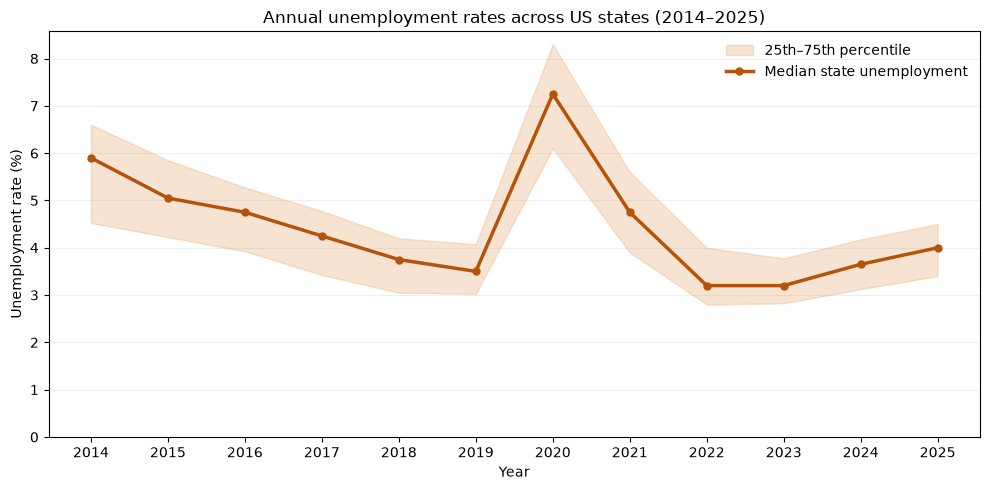

In [15]:
# Summarize annual unemployment rates across states
unemployment_summary = (
    laus_state.groupby("year")["unemployment_rate"]
    .agg(
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.fill_between(
    unemployment_summary["year"],
    unemployment_summary["q25"],
    unemployment_summary["q75"],
    color="#E6A46A",
    alpha=0.3,
    label="25th–75th percentile"
)

ax.plot(
    unemployment_summary["year"],
    unemployment_summary["median"],
    color="#B45309",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Median state unemployment"
)

ax.set(
    title="Annual unemployment rates across US states (2014–2025)",
    xlabel="Year",
    ylabel="Unemployment rate (%)"
)

ax.set_xticks(unemployment_summary["year"])
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()



#### Employment and labor force participation (2014–2025)

The employment–population ratio measures the percentage of the civilian noninstitutional population aged 16 and over that is employed. The labor force participation rate additionally includes unemployed individuals who are actively seeking work.

Median state-level rates are compared over time to illustrate changes in employment and labor market participation independently of state population size.


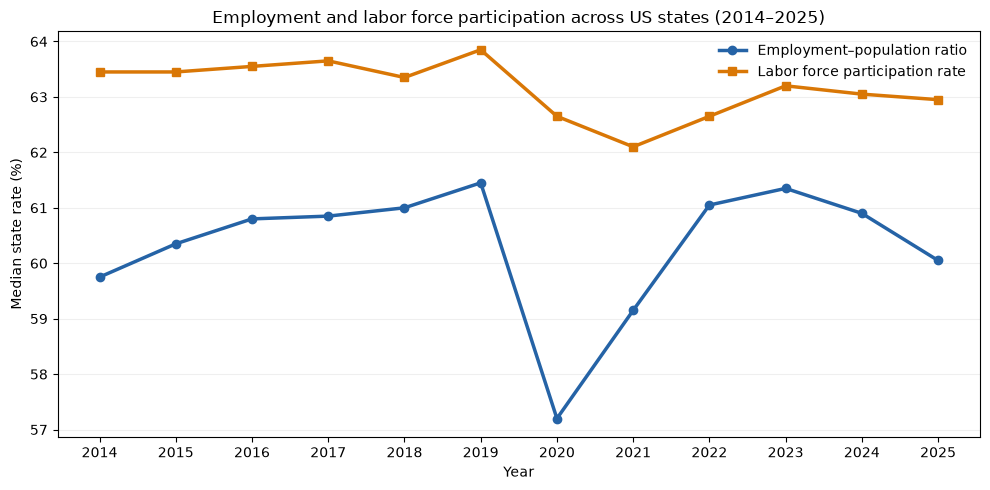

In [16]:
# Calculate annual median labor market rates
participation_summary = (
    laus_state.groupby("year")[
        ["employment_population_ratio", "labor_force_participation_rate"]
    ]
    .median()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    participation_summary["year"],
    participation_summary["employment_population_ratio"],
    color="#2563A6",
    linewidth=2.5,
    marker="o",
    label="Employment–population ratio"
)

ax.plot(
    participation_summary["year"],
    participation_summary["labor_force_participation_rate"],
    color="#D97706",
    linewidth=2.5,
    marker="s",
    label="Labor force participation rate"
)

ax.set(
    title="Employment and labor force participation across US states (2014–2025)",
    xlabel="Year",
    ylabel="Median state rate (%)"
)

ax.set_xticks(participation_summary["year"])
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()


## 5. Validation and export

The final dataset contains annual labor market indicators for 50 US states from 2014 to 2025. Each observation represents one state and year.

The 2025 estimates exclude October due to the federal government shutdown.


In [17]:

# Validate and export the LAUS state-level dataset
assert len(laus_state) == 600
assert laus_state["state_fips"].nunique() == 50
assert laus_state["year"].nunique() == 12
assert not laus_state.duplicated(["state_fips", "year"]).any()
assert laus_state.notna().all().all()

output_dir = PROJECT_ROOT / "data" / "processed" / "economic" / "bls_laus"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "laus_state_2014_2025.csv"
laus_state.to_csv(output_file, index=False)

print("Exported:", output_file)


Exported: C:\Users\stevo\OneDrive\Десктоп\MOS\vaje\Cybersecurity-incident-causations\usa\data\processed\economic\bls_laus\laus_state_2014_2025.csv
